# 07. 실험 4 · 1단계 — 봉우리(언덕) 위치 진단 (RF 없음)

**한 줄 요약:** 실험 3이 실패한 이유가 "보정이 끌어당기는 기준(전체 중앙값)"이었는지 확인한다. 전체 중앙값 대신 **분포의 두 봉우리(활엽 언덕·침엽 언덕) 위치**로 지역 어긋남을 재면, 정답(라벨로 잰 어긋남)에 더 가까운지 본다. **RF 학습 없음. 05의 `_s05` 캐시만 읽는다.**

**쉬운 설명 (인수인계 34-2)**
- 겨울 NDVI 분포 = 활엽 언덕 + 침엽 언덕.
- 숲 구성이 다르면 언덕 **높이**만 바뀌고, 위성이 어긋나면 언덕 **위치**가 옮겨진다.
- 전체 중앙값은 두 경우 모두 움직여서 구별을 못 한다 → 봉화(실제 침엽 60%)를 깎아 버렸다.
- 언덕 위치는 라벨 없이 분포 모양만으로 찾을 수 있다(혼합분포 적합, GMM). 이게 정답에 더 가까우면 2단계(RF로 실제 보정)로 간다.

**세 가지 어긋남 (지역 r − 나머지 7곳, 겨울 NDVI 기준)**

| 이름 | 계산 | 라벨 |
|---|---|---|
| 정답 | 침엽 중앙값 차이와 활엽 중앙값 차이의 평균 | 씀 (채점용) |
| 현재 방식 | 전체 중앙값 차이 (실험 3의 `shift`가 쓴 값) | 안 씀 |
| 새 방식 | GMM 두 봉우리 위치 차이의 평균 | 안 씀 |

**순서:** [1] 설정 → [2] 사전 기록(확정 전엔 여기서 멈춤) → [3] 함수 → [4] 읽기·검산 → [5] 계산 → [6] 주 결과 → [7] 사전 기록과 대조 → [8] 기록만 하는 항목 → [9] 그림·저장

**모두 실행해도 안전하다** (GEE export 없음, 원본 파일 수정 없음). 예상 시간은 [4]의 GMM 1회 시간을 보고 [5]가 출력한다.

In [3]:
# [1] 설정 — 05 [1]과 같은 경로·지역. RF·영상은 쓰지 않는다
import os, json, time, gc, warnings
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt
from google.colab import drive
warnings.filterwarnings('ignore', category=RuntimeWarning)

drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/forest/outputs'

TRAIN_REGIONS = ['inje', 'hongcheon', 'gangneung', 'pyeongchang',
                 'bonghwa', 'geumsan', 'geochang', 'suncheon']
LAT   = {'inje': 38.04, 'hongcheon': 37.75, 'gangneung': 37.71, 'pyeongchang': 37.54,
         'bonghwa': 36.92, 'geumsan': 36.13, 'geochang': 35.71, 'suncheon': 35.01}
LARCH = {'inje': 19.0, 'hongcheon': 37.4, 'gangneung': 11.0, 'pyeongchang': 45.8,
         'bonghwa': 16.7, 'geumsan': 19.5, 'geochang': 11.7, 'suncheon': 0.0}
SEEDS              = [16, 17, 18, 19, 20]
N_TRAIN_PER_REGION = 30_000      # 05와 동일 → '나머지 7곳' 표본이 05 각 폴드의 학습 표본과 같다

# 피처 (4절). 21이 판정용, 나머지는 기록만
FEATS     = [21, 24, 32, 36]
FEAT_NAME = {21: 'w_ndvi', 24: 'd_ndvi', 32: 'w_ndvi_15mu', 36: 'd_ndvi_15mu'}
# 높은 쪽 봉우리가 어느 클래스인가: 겨울 NDVI는 침엽(1)이 높고, 여름−겨울 차이는 활엽(2)이 높다
HIGH_CLASS = {21: 1, 32: 1, 24: 2, 36: 2}
K_MAIN, K_ALT = 2, 3
N_GMM_R = 200_000      # 지역 r의 GMM은 시드별 무작위 20만 (중앙값·정답은 전체). 1차원 봉우리엔 충분
EXP3_WORSE = ['bonghwa', 'geochang', 'suncheon', 'gangneung']   # 32-2: α↑ 오차↑ 그룹 (기록용)

C = {1: 79.25, 2: 101.02, 3: 92.01}   # 이 노트북은 탄소를 계산하지 않는다 (기록용)

missing = [r for r in TRAIN_REGIONS if not os.path.exists(f'{OUT}/{r}_s05.npz')]
assert not missing, f'05 캐시 없음: {missing}'
print('설정 완료. 캐시 8개 확인')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
설정 완료. 캐시 8개 확인


## 실험 4 · 1단계 사전 기록 — 결과를 보기 전에 확정

**읽어 보고 맞으면 [2]의 `CONFIRMED = True`로 바꾼 뒤 실행.** 바꾸고 싶은 곳이 있으면 확정 전에 고칠 것.

| 항목 | 내용 (쉬운 말) |
|---|---|
| 데이터 | 05 캐시 `{지역}_s05.npz` 8개. 지역 r은 캐시 전체(약 60만, GMM만 그중 무작위 20만), 나머지 7곳은 **05 폴드의 학습 표본과 똑같이** 뽑은 21만 |
| 판정 피처 | **겨울 NDVI(21번) 하나.** 24·32·36번은 기록만 |
| 봉우리 수 | **2개**(활엽·침엽). 3개(혼효 포함)는 기록만 |
| 봉우리 ↔ 클래스 | 평균값 순서로 정한다. 겨울 NDVI는 **높은 봉우리 = 침엽**, 낮은 봉우리 = 활엽 (라벨 안 봄) |
| 정답 | 라벨로 잰 침엽 중앙값 차이와 활엽 중앙값 차이의 **평균**. 혼효는 빼고 |
| 오차 | \|추정 어긋남 − 정답\| |
| 시드 | 16–20 (나머지 7곳 표본 + GMM 초기화). GMM은 시작점 3번(`n_init=3`) 중 가장 잘 맞는 것 |
| **통과** | 시드마다 ① 새 방식이 더 정답에 가까운 지역 **6/8 이상** ② 8곳 평균 오차도 새 방식이 작음 ③ **봉화**에서 새 방식이 더 가까움 → **5/5 시드 모두** 성립 |
| 사전 예측 | 봉화는 현재 방식이 정답보다 크게(+) 벗어나고, 새 방식은 정답에 가깝다 |
| 실패 시 | "라벨 없는 보정은 이 데이터에서 한계"로 먼저 보고 → 표본점 방향(35-6) 검토. 기준을 바꾸지 않는다 |
| 기록만 | 봉우리 3개 결과, 다른 피처 결과, 봉우리–라벨 대응 확인, 크기(표준편차) 비율, 실험 3 악화 그룹과의 관계 |

한 번 저장된 `exp4a_prereg.json`은 덮어쓰지 않는다. 바꾸려면 파일을 직접 지우고 이유를 기록할 것.

In [4]:
# [2] 사전 기록 — 확정 전에는 여기서 멈춘다 (정상 정지)
CONFIRMED = True   # ← 위 표를 읽고 맞으면 True로 바꾼다

PREREG = {
    'date': time.strftime('%Y-%m-%d %H:%M'),
    'seen_before_prereg': ('05 [5] 지역별 전체 중앙값(w_ndvi 등), 05 [4] 클래스 비율, 06 실험 3 결과 전체. '
                           '클래스별 중앙값·GMM 봉우리 위치는 보지 않음'),
    'data': '05 캐시 {지역}_s05.npz ×8. 지역 r = 캐시 전체(GMM만 default_rng(seed)로 뽑은 200,000), 나머지 7곳 = 05 [7]과 같은 방식(rng=default_rng(seed), 지역당 30,000)으로 뽑은 210,000',
    'feature_judged': 'w_ndvi (피처 21)',
    'features_record_only': [24, 32, 36],
    'n_components': '2 (판정). 3은 기록만 — 가장 낮은 것=활엽, 가장 높은 것=침엽, 가운데는 무시',
    'peak_to_class': '평균값 순서. w_ndvi는 높은 봉우리=침엽(1), 낮은 봉우리=활엽(2). 라벨 사용 안 함',
    'gmm': "sklearn GaussianMixture(n_components=K, n_init=3, max_iter=500, random_state=seed). 봉우리 위치 = 성분 평균",
    'truth': '0.5 × [(침엽 중앙값_r − 침엽 중앙값_나머지7) + (활엽 중앙값_r − 활엽 중앙값_나머지7)]. 혼효 제외. 라벨 사용(채점 전용)',
    'current': '전체 중앙값_r − 전체 중앙값_나머지7 (실험 3 shift가 쓴 값)',
    'new': '0.5 × [(높은 봉우리_r − 높은 봉우리_나머지7) + (낮은 봉우리_r − 낮은 봉우리_나머지7)]',
    'error': '|추정 − 정답|',
    'seeds': SEEDS,
    'criteria': {
        'P1': '시드마다: |새−정답| < |현재−정답| 인 지역 >= 6/8',
        'P2': '시드마다: 8곳 평균 |새−정답| < 8곳 평균 |현재−정답|',
        'P3': '시드마다: 봉화에서 |새−정답| < |현재−정답|',
        'pass': '5/5 시드에서 P1·P2·P3 모두 → 1단계 통과 → 2단계(RF 재학습, 약 2시간) 진행',
    },
    'prediction': '봉화: 현재 − 정답 > 0 (전체 중앙값이 침엽 60% 구성 때문에 어긋남을 과대 추정), 새 방식은 정답에 더 가까움',
    'record_only': [
        'K=3 결과, 피처 24·32·36 결과 (24·36은 높은 봉우리=활엽)',
        '봉우리–라벨 대응: 각 성분에 배정된 픽셀 중 침엽 비율 (높은 봉우리 > 낮은 봉우리여야 대응이 맞음)',
        '크기 비율 log(sd_r/sd_나머지7): 현재(전체 sd) / 정답(클래스 내 sd 평균) / 새(성분 sd 평균) — 2단계 설계용',
        '현재−정답(구성 오염)의 부호와 실험 3 악화 그룹(봉화·거창·순천·강릉) 일치 수',
    ],
    'limits': ('정답의 클래스 중앙값에도 클래스 안 수종 구성 차이(예: 침엽 속 낙엽송 비율)가 섞여 있다. '
               '캐시에 수종(sp)이 없어 같은 수종 비교는 불가. 정답은 중앙값, 봉우리는 성분 평균이라 정의가 다르나 차이(r−나머지)에서 대부분 상쇄된다고 봄 [추정]'),
    'failure_report': '통과 못 하면 실패라고 먼저 쓰고 → "라벨 없는 보정은 이 데이터에서 한계" 증거로 보고 → 표본점 방향(35-6) 검토. 기준을 결과 보고 바꾸지 않는다',
}

PRE = f'{OUT}/exp4a_prereg.json'
if os.path.exists(PRE):
    print('이미 저장된 사전 기록을 사용 (덮어쓰지 않음):', PRE)
else:
    assert CONFIRMED, '사전 기록을 읽고 CONFIRMED = True로 바꾼 뒤 다시 실행 (정상 정지)'
    json.dump(PREREG, open(PRE, 'w', encoding='utf-8'), ensure_ascii=False, indent=2)
    print('사전 기록 저장:', PRE)
print(json.dumps(json.load(open(PRE, encoding='utf-8')), ensure_ascii=False, indent=2))

사전 기록 저장: /content/drive/MyDrive/forest/outputs/exp4a_prereg.json
{
  "date": "2026-10-03 06:04",
  "seen_before_prereg": "05 [5] 지역별 전체 중앙값(w_ndvi 등), 05 [4] 클래스 비율, 06 실험 3 결과 전체. 클래스별 중앙값·GMM 봉우리 위치는 보지 않음",
  "data": "05 캐시 {지역}_s05.npz ×8. 지역 r = 캐시 전체(GMM만 default_rng(seed)로 뽑은 200,000), 나머지 7곳 = 05 [7]과 같은 방식(rng=default_rng(seed), 지역당 30,000)으로 뽑은 210,000",
  "feature_judged": "w_ndvi (피처 21)",
  "features_record_only": [
    24,
    32,
    36
  ],
  "n_components": "2 (판정). 3은 기록만 — 가장 낮은 것=활엽, 가장 높은 것=침엽, 가운데는 무시",
  "peak_to_class": "평균값 순서. w_ndvi는 높은 봉우리=침엽(1), 낮은 봉우리=활엽(2). 라벨 사용 안 함",
  "gmm": "sklearn GaussianMixture(n_components=K, n_init=3, max_iter=500, random_state=seed). 봉우리 위치 = 성분 평균",
  "truth": "0.5 × [(침엽 중앙값_r − 침엽 중앙값_나머지7) + (활엽 중앙값_r − 활엽 중앙값_나머지7)]. 혼효 제외. 라벨 사용(채점 전용)",
  "current": "전체 중앙값_r − 전체 중앙값_나머지7 (실험 3 shift가 쓴 값)",
  "new": "0.5 × [(높은 봉우리_r − 높은 봉우리_나머지7) + (낮은 봉우리_r − 낮은 봉우리_나머지7)]",
  "error": "|추정 − 정답|",
  "seeds": [
    16,
    17,
    

In [5]:
# [3] 함수
def rest_sample(test, seed, S):
    # 05 [7]과 같은 순서·같은 rng로 '나머지 7곳' 표본을 뽑는다 → 05 각 폴드의 학습 표본과 동일
    rng = np.random.default_rng(seed)
    Xs, ys = [], []
    for r in TRAIN_REGIONS:
        if r == test: continue
        n = len(S[r]['y'])
        i = rng.choice(n, size=min(N_TRAIN_PER_REGION, n), replace=False)
        Xs.append(S[r]['X'][i]); ys.append(S[r]['y'][i])
    return np.concatenate(Xs), np.concatenate(ys)

def fit_peaks(x, K, seed):
    # 1차원 GMM → (평균, 표준편차, 비중)을 평균값 오름차순으로. 라벨 사용 안 함
    g = GaussianMixture(n_components=K, n_init=3, max_iter=500, random_state=seed).fit(x.reshape(-1, 1))
    o = np.argsort(g.means_.ravel())
    mu = g.means_.ravel()[o]
    sd = np.sqrt(g.covariances_.reshape(K, -1)[:, 0])[o]
    w  = g.weights_[o]
    comp = np.argsort(o)[g.predict(x.reshape(-1, 1))]   # 정렬된 성분 번호 (0=가장 낮음)
    return mu, sd, w, comp, bool(g.converged_)

def lowhigh(v):
    # K개 성분 중 가장 낮은 것과 가장 높은 것 (K=3이면 가운데는 무시)
    return v[0], v[-1]

def class_stats(x, y, f):
    # 피처 f에서 '높은 쪽 클래스'와 '낮은 쪽 클래스'의 중앙값·표준편차 (라벨 사용 — 정답용)
    hi = HIGH_CLASS[f]; lo = 3 - hi                     # 1↔2
    return (np.median(x[y == lo]), np.median(x[y == hi]),
            x[y == lo].std(), x[y == hi].std())

def conif_share(comp, y, k):
    # 성분 k에 배정된 픽셀 중 침엽 비율 (침엽+활엽 기준) — 대응 확인용, 기록만
    m = (comp == k) & (y <= 2)
    return float((y[m] == 1).mean()) if m.any() else np.nan

print('함수 정의 완료')

함수 정의 완료


In [6]:
# [4] 캐시 읽기 + 검산 (05와 같은 캐시인지, GMM이 봉우리를 제대로 찾는지)
assert os.path.exists(f'{OUT}/exp4a_prereg.json'), '[2] 사전 기록을 먼저 확정 (정상 정지)'

t0 = time.time()
S = {}
for r in TRAIN_REGIONS:
    z = np.load(f'{OUT}/{r}_s05.npz')
    S[r] = dict(X=z['X'][:, FEATS].copy(), y=z['y'].copy())
    del z; gc.collect()
COL = {f: k for k, f in enumerate(FEATS)}           # 원래 피처 번호 → S의 열 번호
print(f'캐시 읽기 {time.time()-t0:.0f}초')

# ① 05 [4] 표의 n_sample과 같은 캐시인가
N_REF = {'inje': 600263, 'hongcheon': 599525, 'gangneung': 600079, 'pyeongchang': 600530,
         'bonghwa': 599540, 'geumsan': 600247, 'geochang': 601114, 'suncheon': 600845}
# ② 05 [5]의 지역별 전체 w_ndvi 중앙값과 같은가
W_REF = {'inje': 0.460, 'hongcheon': 0.418, 'gangneung': 0.536, 'pyeongchang': 0.378,
         'bonghwa': 0.632, 'geumsan': 0.456, 'geochang': 0.623, 'suncheon': 0.657}
for r in TRAIN_REGIONS:
    n = len(S[r]['y']); w = np.median(S[r]['X'][:, COL[21]])
    assert n == N_REF[r], f'{r}: 표본 수 {n} ≠ 05의 {N_REF[r]}'
    assert abs(w - W_REF[r]) < 0.0015, f'{r}: w_ndvi 중앙값 {w:.4f} ≠ 05의 {W_REF[r]}'
    assert set(np.unique(S[r]['y'])) <= {1, 2, 3}
print('① 표본 수 8곳 모두 05와 일치   ② 전체 w_ndvi 중앙값 8곳 모두 05 [5]와 일치')

# ③ 가짜 데이터: 위치를 아는 두 봉우리를 GMM이 찾는가 (봉우리 위치 0.40 / 0.65, 비중 4:6)
rng = np.random.default_rng(0)
xs = np.concatenate([rng.normal(0.40, 0.06, 240_000), rng.normal(0.65, 0.05, 360_000)]).astype('float32')
t1 = time.time()
mu, sd, w, comp, conv = fit_peaks(xs, 2, 0)
T_GMM = time.time() - t1
assert conv and abs(mu[0] - 0.40) < 0.005 and abs(mu[1] - 0.65) < 0.005, mu
# ④ 비중만 바꾸면(구성 차이) 봉우리는 그대로, 중앙값은 움직이는가 — 이 실험의 논리 확인
xs2 = np.concatenate([rng.normal(0.40, 0.06, 120_000), rng.normal(0.65, 0.05, 480_000)]).astype('float32')
mu2 = fit_peaks(xs2, 2, 0)[0]
d_med, d_peak = np.median(xs2) - np.median(xs), np.mean(mu2 - mu)
assert abs(d_peak) < 0.005 and d_med > 0.02, (d_med, d_peak)
print(f'③ 가짜 봉우리 복원: {mu[0]:.3f} / {mu[1]:.3f} (정답 0.400 / 0.650), GMM 60만 1회 {T_GMM:.1f}초')
print(f'④ 구성만 바꿈: 중앙값 {d_med:+.3f} 이동, 봉우리 {d_peak:+.4f} 이동 → 논리 확인')
print('검산 통과')
del xs, xs2

캐시 읽기 34초
① 표본 수 8곳 모두 05와 일치   ② 전체 w_ndvi 중앙값 8곳 모두 05 [5]와 일치
③ 가짜 봉우리 복원: 0.400 / 0.650 (정답 0.400 / 0.650), GMM 60만 1회 3.2초
④ 구성만 바꿈: 중앙값 +0.032 이동, 봉우리 +0.0004 이동 → 논리 확인
검산 통과


In [7]:
# [5] 계산 — 시드 × 지역 × 피처 × 봉우리 수(2, 3)
n_fit = len(SEEDS) * len(TRAIN_REGIONS) * len(FEATS) * 2 * 2
print(f'GMM {n_fit}회 (지역 r 20만 + 나머지 21만), 예상 약 {n_fit * T_GMM * 0.3 / 60:.0f}–{n_fit * T_GMM * 0.8 / 60:.0f}분 '
      '([4]의 1회 시간 기준)\n')

rows = []
t0 = time.time()
for si, seed in enumerate(SEEDS):
    for r in TRAIN_REGIONS:
        Xa, ya = rest_sample(r, seed, S)           # 나머지 7곳
        Xb, yb = S[r]['X'], S[r]['y']               # 지역 r
        ib = np.random.default_rng(seed).choice(len(yb), size=N_GMM_R, replace=False)   # GMM용 20만
        for f in FEATS:
            xa, xb = Xa[:, COL[f]], Xb[:, COL[f]]
            lo_a, hi_a, slo_a, shi_a = class_stats(xa, ya, f)
            lo_b, hi_b, slo_b, shi_b = class_stats(xb, yb, f)
            base = dict(seed=seed, region=r, feat=f,
                        truth=0.5 * ((hi_b - hi_a) + (lo_b - lo_a)),
                        truth_hi=hi_b - hi_a, truth_lo=lo_b - lo_a,
                        current=float(np.median(xb) - np.median(xa)),
                        lsd_truth=0.5 * (np.log(shi_b / shi_a) + np.log(slo_b / slo_a)),
                        lsd_current=float(np.log(xb.std() / xa.std())))
            for K in (K_MAIN, K_ALT):
                mua, sda, wa, ca, cva = fit_peaks(xa, K, seed)
                mub, sdb, wb, cb, cvb = fit_peaks(xb[ib], K, seed)
                (la, ha), (lb, hb) = lowhigh(mua), lowhigh(mub)
                (sla, sha), (slb, shb) = lowhigh(sda), lowhigh(sdb)
                rows.append(dict(base, K=K,
                    new=0.5 * ((hb - ha) + (lb - la)), new_hi=hb - ha, new_lo=lb - la,
                    lsd_new=0.5 * (np.log(shb / sha) + np.log(slb / sla)),
                    peak_lo_r=lb, peak_hi_r=hb, peak_lo_rest=la, peak_hi_rest=ha,
                    w_hi_r=float(wb[-1]),
                    conif_in_hi_r=conif_share(cb, yb[ib], K - 1), conif_in_lo_r=conif_share(cb, yb[ib], 0),
                    converged=cva and cvb))
        del Xa, ya; gc.collect()
    print(f'  시드 {seed} 완료 ({(time.time()-t0)/60:.1f}분)')

R = pd.DataFrame(rows)
R['err_cur'] = (R['current'] - R['truth']).abs()
R['err_new'] = (R['new'] - R['truth']).abs()
R['contam']  = R['current'] - R['truth']          # 현재 방식의 구성 오염 (+면 과대)
R.to_csv(f'{OUT}/exp4a_all.csv', index=False)
print(f'\n완료 {len(R)}행, 수렴 실패 {int((~R["converged"]).sum())}건 → exp4a_all.csv')

GMM 640회 (지역 r 20만 + 나머지 21만), 예상 약 10–27분 ([4]의 1회 시간 기준)

  시드 16 완료 (6.9분)
  시드 17 완료 (14.0분)
  시드 18 완료 (21.0분)
  시드 19 완료 (27.9분)
  시드 20 완료 (34.9분)

완료 320행, 수렴 실패 0건 → exp4a_all.csv


In [8]:
# [6] 주 결과 — 겨울 NDVI(21), 봉우리 2개. 값은 5시드 평균 (NDVI 단위)
M = R[(R.feat == 21) & (R.K == K_MAIN)].copy()
g = M.groupby('region', sort=False)
tab = pd.DataFrame({
    '정답': g['truth'].mean(), '현재(중앙값)': g['current'].mean(), '새(봉우리)': g['new'].mean(),
    '|현재−정답|': g['err_cur'].mean(), '|새−정답|': g['err_new'].mean(),
    '새가 가까운 시드': g.apply(lambda d: f'{int((d.err_new < d.err_cur).sum())}/{len(d)}'),
    '봉우리 r 낮/높': g.apply(lambda d: f'{d.peak_lo_r.mean():.3f}/{d.peak_hi_r.mean():.3f}'),
    '높은봉 비중': g['w_hi_r'].mean(),
}).loc[TRAIN_REGIONS]
print(tab.round(4).to_string())
print('\n정답 = 클래스별(침엽·활엽) 중앙값 차이의 평균, r − 나머지 7곳. 양수 = r의 겨울 NDVI가 더 높게 찍힘')

                 정답  현재(중앙값)  새(봉우리)  |현재−정답|  |새−정답| 새가 가까운 시드    봉우리 r 낮/높  높은봉 비중
region                                                                              
inje        -0.0535  -0.0599 -0.0615   0.0064  0.0080       0/5  0.365/0.670  0.3947
hongcheon   -0.1012  -0.1111 -0.0846   0.0099  0.0166       0/5  0.359/0.633  0.3307
gangneung    0.0286   0.0265  0.0122   0.0022  0.0164       0/5  0.431/0.731  0.3965
pyeongchang -0.1630  -0.1539 -0.1029   0.0091  0.0601       0/5  0.316/0.629  0.3092
bonghwa      0.0552   0.1334  0.0410   0.0782  0.0142       5/5  0.451/0.757  0.5181
geumsan     -0.0670  -0.0715 -0.0458   0.0045  0.0212       0/5  0.423/0.631  0.3152
geochang     0.0610   0.1244  0.0515   0.0635  0.0095       5/5  0.466/0.750  0.5010
suncheon     0.1016   0.1697  0.0681   0.0680  0.0335       5/5  0.514/0.741  0.5526

정답 = 클래스별(침엽·활엽) 중앙값 차이의 평균, r − 나머지 7곳. 양수 = r의 겨울 NDVI가 더 높게 찍힘


/tmp/ipykernel_801/1650199824.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  '새가 가까운 시드': g.apply(lambda d: f'{int((d.err_new < d.err_cur).sum())}/{len(d)}'),
/tmp/ipykernel_801/1650199824.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  '봉우리 r 낮/높': g.apply(lambda d: f'{d.peak_lo_r.mean():.3f}/{d.peak_hi_r.mean():.3f}'),


In [9]:
# [7] 사전 기록과 대조 — 규칙 그대로 계산만. 판정 문장은 사람이 쓴다
out = []
for seed in SEEDS:
    d = M[M.seed == seed].set_index('region').loc[TRAIN_REGIONS]
    p1n = int((d.err_new < d.err_cur).sum())
    p2  = bool(d.err_new.mean() < d.err_cur.mean())
    p3  = bool(d.loc['bonghwa', 'err_new'] < d.loc['bonghwa', 'err_cur'])
    out.append(dict(seed=seed, P1_regions=p1n, P1=p1n >= 6, mean_err_cur=d.err_cur.mean(),
                    mean_err_new=d.err_new.mean(), P2=p2, P3_bonghwa=p3,
                    ALL=(p1n >= 6) and p2 and p3))
J = pd.DataFrame(out)
print(J.round(4).to_string(index=False))
PASS = bool(J.ALL.all())
print(f'\n통과 = 5/5 시드에서 P1·P2·P3 모두: {int(J.ALL.sum())}/5 → {"통과 (2단계로)" if PASS else "미통과"}')
b = M[M.region == 'bonghwa']
print(f'사전 예측 (봉화 현재−정답 > 0): {b.contam.mean():+.4f}, 양수 {int((b.contam > 0).sum())}/5 시드')

 seed  P1_regions    P1  mean_err_cur  mean_err_new   P2  P3_bonghwa   ALL
   16           3 False        0.0303        0.0221 True        True False
   17           3 False        0.0298        0.0227 True        True False
   18           3 False        0.0303        0.0227 True        True False
   19           3 False        0.0304        0.0218 True        True False
   20           3 False        0.0303        0.0229 True        True False

통과 = 5/5 시드에서 P1·P2·P3 모두: 0/5 → 미통과
사전 예측 (봉화 현재−정답 > 0): +0.0782, 양수 5/5 시드


In [10]:
# [8] 기록만 하는 항목 (판정 없음)
def summary(df):
    n_better = (df.err_new < df.err_cur).groupby(df.seed).sum()
    return f'새가 가까운 지역 {"/".join(str(int(v)) for v in n_better)} (시드별, /8), 평균 오차 현재 {df.err_cur.mean():.4f} / 새 {df.err_new.mean():.4f}'

print('■ 피처·봉우리 수별')
for f in FEATS:
    for K in (K_MAIN, K_ALT):
        df = R[(R.feat == f) & (R.K == K)]
        print(f'  {FEAT_NAME[f]:12s} K={K}: {summary(df)}')

print('\n■ 봉우리–라벨 대응 (w_ndvi, K=2): 높은 봉우리에 배정된 픽셀 중 침엽 비율 > 낮은 봉우리여야 함')
for r in TRAIN_REGIONS:
    d = M[M.region == r]
    print(f'  {r:12s} 높은봉 침엽 {d.conif_in_hi_r.mean():.2f}  낮은봉 침엽 {d.conif_in_lo_r.mean():.2f}'
          f'  {"맞음" if (d.conif_in_hi_r > d.conif_in_lo_r).all() else "어긋남"}')

print('\n■ 크기 비율 log(sd_r / sd_나머지7), w_ndvi K=2 — 2단계 설계용')
s = M.groupby('region', sort=False)[['lsd_truth', 'lsd_current', 'lsd_new']].mean().loc[TRAIN_REGIONS]
print(s.round(3).to_string())
print(f'  |현재−정답| 평균 {np.abs(s.lsd_current - s.lsd_truth).mean():.3f},  |새−정답| 평균 {np.abs(s.lsd_new - s.lsd_truth).mean():.3f}')

print('\n■ 현재 방식의 구성 오염(현재−정답) 부호 vs 실험 3 악화 그룹 (봉화·거창·순천·강릉 = + 예상)')
c = M.groupby('region', sort=False)['contam'].mean().loc[TRAIN_REGIONS]
match = sum((c[r] > 0) == (r in EXP3_WORSE) for r in TRAIN_REGIONS)
print('  ' + '  '.join(f'{r[:4]} {c[r]:+.4f}' for r in TRAIN_REGIONS))
print(f'  부호 일치 {match}/8')

■ 피처·봉우리 수별
  w_ndvi       K=2: 새가 가까운 지역 3/3/3/3/3 (시드별, /8), 평균 오차 현재 0.0302 / 새 0.0224
  w_ndvi       K=3: 새가 가까운 지역 4/3/3/6/3 (시드별, /8), 평균 오차 현재 0.0302 / 새 0.0192
  d_ndvi       K=2: 새가 가까운 지역 4/3/3/3/3 (시드별, /8), 평균 오차 현재 0.0329 / 새 0.0239
  d_ndvi       K=3: 새가 가까운 지역 3/3/3/3/3 (시드별, /8), 평균 오차 현재 0.0329 / 새 0.0258
  w_ndvi_15mu  K=2: 새가 가까운 지역 4/3/3/4/3 (시드별, /8), 평균 오차 현재 0.0144 / 새 0.0087
  w_ndvi_15mu  K=3: 새가 가까운 지역 4/3/2/3/4 (시드별, /8), 평균 오차 현재 0.0144 / 새 0.0119
  d_ndvi_15mu  K=2: 새가 가까운 지역 4/4/4/4/5 (시드별, /8), 평균 오차 현재 0.0172 / 새 0.0083
  d_ndvi_15mu  K=3: 새가 가까운 지역 5/4/3/4/4 (시드별, /8), 평균 오차 현재 0.0172 / 새 0.0117

■ 봉우리–라벨 대응 (w_ndvi, K=2): 높은 봉우리에 배정된 픽셀 중 침엽 비율 > 낮은 봉우리여야 함
  inje         높은봉 침엽 0.87  낮은봉 침엽 0.30  맞음
  hongcheon    높은봉 침엽 0.77  낮은봉 침엽 0.29  맞음
  gangneung    높은봉 침엽 0.83  낮은봉 침엽 0.23  맞음
  pyeongchang  높은봉 침엽 0.82  낮은봉 침엽 0.37  맞음
  bonghwa      높은봉 침엽 0.90  낮은봉 침엽 0.37  맞음
  geumsan      높은봉 침엽 0.68  낮은봉 침엽 0.27  맞음
  geochang     높은봉 침엽 0.93  낮은봉 침엽 0

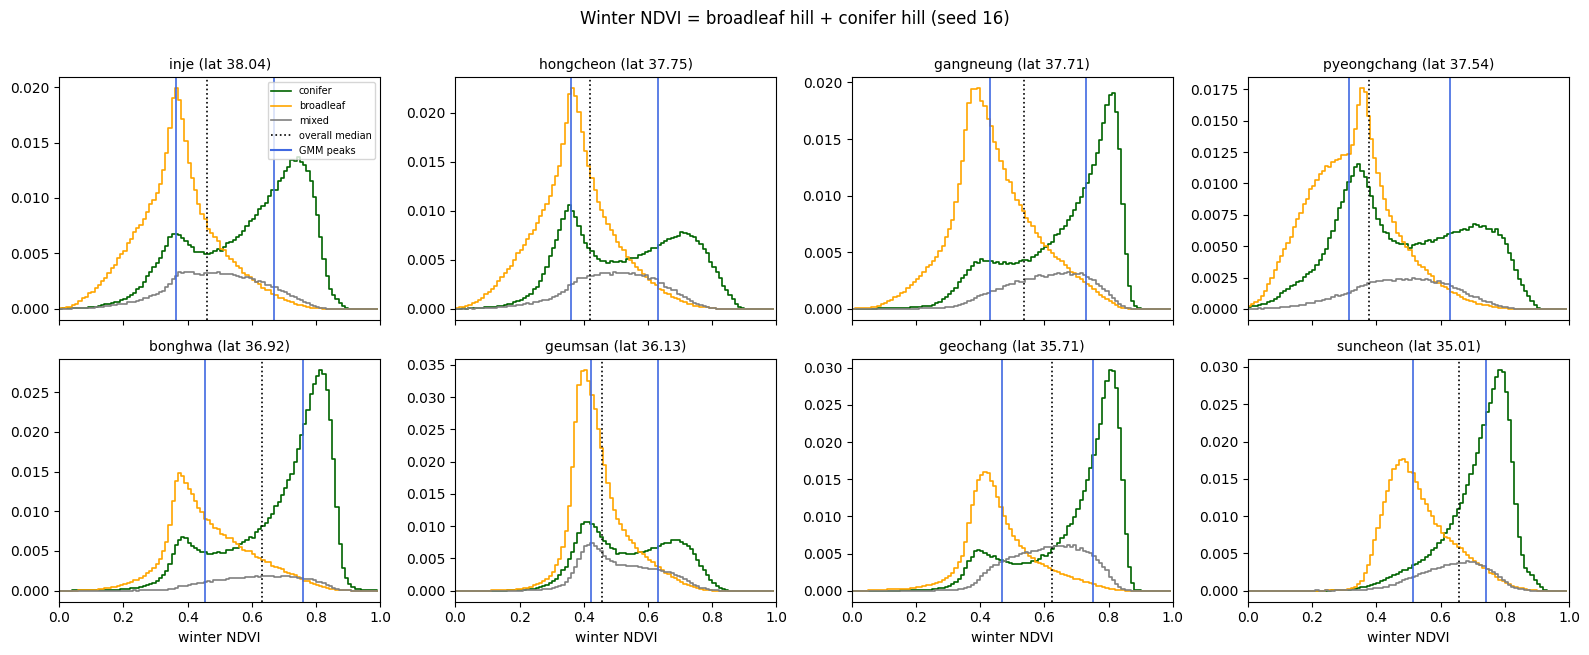

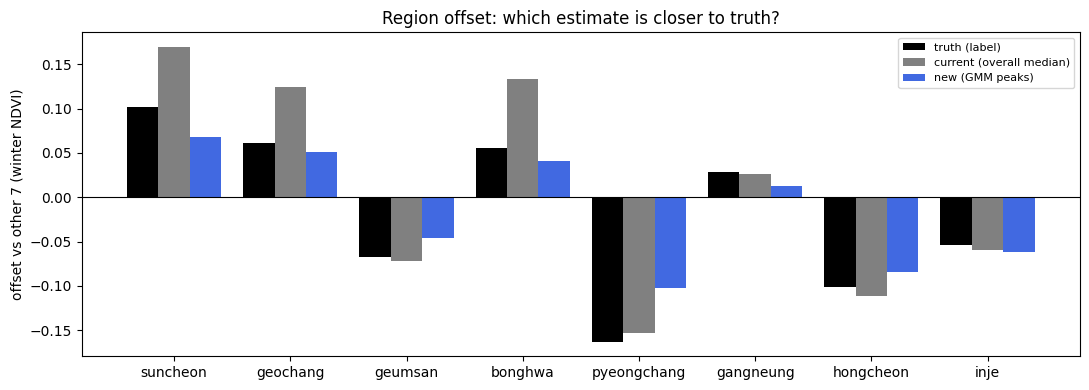

저장: exp4a_all.csv, exp4a_by_region.csv, exp4a_by_seed.csv, exp4a_hills.png, exp4a_offset.png
→ [6]–[8] 출력과 그림 2장을 새 채팅에 붙여넣기


In [11]:
# [9] 그림·저장 (Colab 기본 폰트에 한글이 없어 영문 표기)
# 그림 1: 지역별 겨울 NDVI 분포 = 두 언덕. 클래스별 히스토그램 + 전체 중앙값(점선) + GMM 봉우리(실선), 시드 16
bins = np.linspace(0, 1, 101)
fig, axs = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True)
for ax, r in zip(axs.ravel(), TRAIN_REGIONS):
    x, y = S[r]['X'][:, COL[21]], S[r]['y']
    for k, col, lab in ((1, 'darkgreen', 'conifer'), (2, 'orange', 'broadleaf'), (3, 'gray', 'mixed')):
        h, _ = np.histogram(x[y == k], bins=bins)
        ax.step(bins[:-1], h / len(x), where='post', c=col, lw=1.2, label=lab)
    d = M[(M.region == r) & (M.seed == SEEDS[0])].iloc[0]
    ax.axvline(np.median(x), c='k', ls=':', lw=1.2, label='overall median')
    for p in (d.peak_lo_r, d.peak_hi_r):
        ax.axvline(p, c='royalblue', lw=1.2)
    ax.set_title(f'{r} (lat {LAT[r]})', fontsize=10)
    ax.set_xlim(0, 1)
axs[0, 0].plot([], [], c='royalblue', label='GMM peaks')
axs[0, 0].legend(fontsize=7)
for ax in axs[1]: ax.set_xlabel('winter NDVI')
plt.suptitle('Winter NDVI = broadleaf hill + conifer hill (seed 16)', y=1.0)
plt.tight_layout(); plt.savefig(f'{OUT}/exp4a_hills.png', dpi=130); plt.show()

# 그림 2: 지역별 어긋남 — 정답 / 현재 / 새 (5시드 평균)
lat = np.array([LAT[r] for r in TRAIN_REGIONS]); o = np.argsort(lat)
xpos = np.arange(len(TRAIN_REGIONS))
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(xpos - .27, tab['정답'].values[o], .27, color='k', label='truth (label)')
ax.bar(xpos,       tab['현재(중앙값)'].values[o], .27, color='gray', label='current (overall median)')
ax.bar(xpos + .27, tab['새(봉우리)'].values[o], .27, color='royalblue', label='new (GMM peaks)')
ax.axhline(0, c='k', lw=.8)
ax.set_xticks(xpos); ax.set_xticklabels([TRAIN_REGIONS[i] for i in o])
ax.set_ylabel('offset vs other 7 (winter NDVI)'); ax.set_title('Region offset: which estimate is closer to truth?')
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/exp4a_offset.png', dpi=150); plt.show()

tab.to_csv(f'{OUT}/exp4a_by_region.csv')
J.to_csv(f'{OUT}/exp4a_by_seed.csv', index=False)
print('저장: exp4a_all.csv, exp4a_by_region.csv, exp4a_by_seed.csv, exp4a_hills.png, exp4a_offset.png')
print('→ [6]–[8] 출력과 그림 2장을 새 채팅에 붙여넣기')